# How far bans and token vetoes push Qwen3-8B: a runnable look at `method.py` (token walk)

**Artifact** `art_ccAbfJVcv0LO`, step 4 of iteration 3 of an LLM-creativity study.
**Model:** `Qwen/Qwen3-8B`, in bf16 for the path tasks and on the official FP8 checkpoint for the bench tasks.

The question is how far one can push an LLM away from its *default* algorithm, and whether any knob gives a truly novel one. The six tasks, each with the algorithm the model writes when nothing is banned:
- **T1** grid path: BFS
- **T2** weighted shortest path: Dijkstra
- **T03** k-th smallest: full sort
- **T04** substring search: naive scan
- **T06** find duplicate: hash set
- **T10** connected components: union-find

| arm | what it does | full-run result |
|---|---|---|
| **4b token walk** | Under a neutral prompt (no ban text), a vLLM logits processor (`src/veto.py`) persistently vetoes the token n-gram most distinctive of the default algorithm. The algorithm the model lands on next is vetoed in the next step. | The veto is **exact**: 0 banned-sequence occurrences in 1,450 vetoed generations. Yet the walk **stalled on all 6 tasks**, at step 1 on five and at step 2 on T06. The model renamed variables, respelled the vetoed string or wrote broken code. A matched **sham** veto left the default untouched. |
| **4a prompt reach** | Leave-one-survivor and two-step ban lists in the prompt. Each list is scored as *will* (share writing the allowed algorithm) against forced *can*. | Prediction C3 (will ≤ 0.10 at rung ≥ 3 wherever can ≥ 0.7) is **disconfirmed** by T03 quickselect and T10 BFS. |
| **4c long-form novelty** | "Make a (fully) novel algorithm …" with a 2,000-word rationale, thinking off and on, 575 outputs. | 84% *claim* a new algorithm. **0 novel programs** survive two blind judges and a manual audit. |

**What `method.py` is.** It is the artifact's command-line entry point.
- Every GPU stage is a `subprocess` call into `src/*.py`: the vLLM server, veto unit tests, phases A/B, long-form generation, audit and analysis.
- The CPU-only `outputs` command, `assemble_outputs()`, turns the saved per-program rows and result files into `method_out.json`. It is the default when the script gets no argument.

The GPU stages need Qwen3-8B on a 23 GB GPU and hours of generation. This notebook therefore runs **what `uv run method.py` runs with no argument**:
- `assemble_outputs()` runs on a curated subset of **one dataset**, `token_walk`: 100 programs that cover all 35 task × arm × step × round cells of the walk, sham and fixed-TOP5 arms.
- The artifact's real `results/*.json`, `predictions/*.json` and `commitments.log` are loaded too. So the metadata, the figures and the sha256 commitment-chain check are the full-run ones.

**Changes to the original code (kept minimal, each marked `# was:` in the code):**
1. File reads go through `exists(p)` / `read_text(p)` over the downloaded `mini_demo_data.json`, instead of `Path.exists()` / `Path.read_text()`.
2. The names `method.py` imports from `src/config.py`, `src/prompts.py` and `src/commit.py` are copied into cells. Two steps need the Qwen3 tokenizer: the neutral-twin padding and the prompt token ids. For those, the demo data carries the precomputed results.
3. `sys.argv` is replaced by `COMMAND` / `COMMAND_ARGS` in the config cell, and `__file__` by the current directory.
4. At the end, tables and the artifact's own figure code (`src/figures.py`) show the results inline.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru - NOT on Colab, always install (method.py logs through it)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib - pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import json
import subprocess
import sys
from collections import Counter
from pathlib import Path

ROOT = Path.cwd()                         # was: Path(__file__).resolve().parent  (a notebook has no __file__)
# sys.path.insert(0, str(ROOT / "src"))   # not needed: the src/ names method.py uses are defined in this notebook

from loguru import logger  # noqa: E402

# from config import (ALL_TASKS, DATA, PRED, RESULTS, TASKS, read_jsonl, setup_logging, utc_now,  # noqa: E402
#                     write_json)
# -> defined in the "Shared names from src/config.py" cell below, on top of the downloaded demo data

PY = str(ROOT / ".venv" / "bin" / "python")

# notebook additions: what the copied src/config.py / src/commit.py helpers need, plus tables and figures
import hashlib
import textwrap
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import PurePosixPath
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/experiment-18/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if "files" not in data:
    # the URL can still serve an older demo file of this artifact (a different layout, published before this
    # notebook's data was pushed): use the copy of mini_demo_data.json that ships next to this notebook
    print("GitHub file has an older layout, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())

about = data["about"]
print(about["title"])
print(f"dataset {about['dataset']!r}: {about['n_examples']} demo rows {about['examples']}")
print(f"full run: {about['full_run_rows']} in {about['n_cells']} cells; {len(data['files'])} artifact files shipped")

GitHub file has an older layout, using local mini_demo_data.json
Token-walk demo data for code_demo.ipynb (art_ccAbfJVcv0LO: how far bans and token vetoes push Qwen/Qwen3-8B, iteration 3 step 4)
dataset 'token_walk': 100 demo rows {'data/samples_walk.jsonl': 81, 'data/samples_sham.jsonl': 10, 'data/samples_fixed_top5.jsonl': 9}
full run: {'data/samples_walk.jsonl': 1400, 'data/samples_sham.jsonl': 200, 'data/samples_fixed_top5.jsonl': 150} in 35 cells; 75 artifact files shipped


## Configuration

`method.py` is a command-line program. This cell stands in for its command line, plus one knob for how much of the demo data goes through it.

- **`COMMAND` / `COMMAND_ARGS`** are the sub-command and its arguments: `uv run method.py <COMMAND> <COMMAND_ARGS...>`.
  - Only `outputs` (the default) and `help` run here.
  - `s0`, `server`, `unit`, `phase`, `longform`, `audit` and `analyze` start `src/*.py` scripts under the artifact's `.venv`, with vLLM on a GPU.
- **`MAX_ROWS_PER_FILE`** caps the rows read from each `data/samples_<arm>.jsonl` in the demo data.
  - `None` takes all 100 demo rows: 81 walk, 10 sham and 9 fixed-TOP5.
  - The rows are interleaved across cells, so even a small cap covers several cells.
  - The original run has 1,400 walk + 200 sham + 150 fixed-TOP5 rows, N = 50 per cell: 1,750 `token_walk` examples. `build_mini_demo_data.py --n-rows 1750` packs all of them (2.9 MB). This notebook then processes them in a few seconds and reproduces the artifact's `token_walk` dataset exactly.

In [5]:
COMMAND = "outputs"            # method.py sub-command; "outputs" = the default with no argument (no GPU needed)
COMMAND_ARGS: list[str] = []   # further CLI arguments, e.g. ["bf16", "start"] for `server` (GPU commands only)

MAX_ROWS_PER_FILE = None       # rows per data/samples_<arm>.jsonl; None = all 100 demo rows (81 walk, 10 sham, 9 top5)
# scaling runs: 1 row/file -> 3 examples, 10 -> 29, None -> 100; each ~15 s including installs (the cell itself < 1 s)
# original full run: every row = 1,400 walk + 200 sham + 150 fixed-TOP5 (the artifact's data/samples_*.jsonl)

## Shared names from `src/config.py`

`method.py` imports the task registry, the path constants and a few helpers from `src/config.py`. They are copied here with one change: **the artifact's files are virtual.**

`REPO` is the artifact's root inside `mini_demo_data.json`. Paths under `data/`, `results/`, `predictions/` and `inputs/`, and `commitments.log`, are keys of `data["files"]`. Two helpers read them:
- `exists(p)` stands in for `Path.exists()`.
- `read_text(p)` stands in for `Path.read_text()`. It re-creates a file's text exactly as the artifact wrote it:
  - JSON files: `json.dumps(obj, indent=1)`, as `write_json` did;
  - JSONL files: one `json.dumps(row)` line per row, as `append_jsonl` did;
  - everything else: the verbatim text.

Because the text is exact, `sha256_file()` still reproduces the sha256 values committed in `commitments.log`.

The notebook's outputs are real files in the working directory: `method_out.json`, `logs/` and `figures/`.

The **task registry** lists the six tasks, each with its *default* algorithm (the one the model writes when nothing is banned), its catalogue and the display names that go into ban sentences. The bench entries are filled from the frozen bench `spec.json` files.

In [6]:
# ---- the artifact's files, shipped inside mini_demo_data.json (artifact-relative path -> content)
FILES: dict[str, Any] = data["files"]
for _k in [k for k in FILES if k.endswith(".jsonl")]:
    FILES[_k] = FILES[_k][:MAX_ROWS_PER_FILE]          # config: rows per data/samples_<arm>.jsonl


def exists(p) -> bool:
    """Notebook stand-in for Path.exists(): is artifact file `p` in the demo data?"""
    return str(p) in FILES


def read_text(p) -> str:
    """Notebook stand-in for Path.read_text(): the file's text, re-created exactly as the artifact wrote it."""
    v = FILES[str(p)]
    if str(p).endswith(".jsonl"):
        return "".join(json.dumps(r) + "\n" for r in v)   # append_jsonl()
    if str(p).endswith(".json"):
        return json.dumps(v, indent=1, default=str)       # write_json()
    return v                                              # commitments.log, src/*.py: verbatim text


# ================================================================ src/config.py (the parts method.py needs)
REPO = PurePosixPath(".")   # was: ROOT = Path(__file__).resolve().parent.parent  (the artifact folder, now virtual)
INPUTS = REPO / "inputs"
DATA = REPO / "data"
RESULTS = REPO / "results"
PRED = REPO / "predictions"
COMMIT_LOG = REPO / "commitments.log"
FIGS = ROOT / "figures"     # real output folders of this notebook
LOGS = ROOT / "logs"
for _d in (FIGS, LOGS):     # was: (DATA, RESULTS, PRED, FIGS, LOGS)
    _d.mkdir(parents=True, exist_ok=True)

BENCH_DIR = INPUTS / "bench"          # copy of exp11 bench (frozen; verified against bench/commitment.json)

# ------------------------------------------------------------------------------------------------ templates
W_TEMPLATES = {
    "W1": "Do not use {N} for this task.",
    "W2": "Your solution must not rely on {N}.",
    "W3": "Avoid {N} entirely.",
    "W4": "{N} is not allowed here.",
    "W5": "Write a correct solution that does not use {N}.",
}
W_IDS = list(W_TEMPLATES)
FILLER = " ."   # exp7 neutral-padding filler

LF_PROMPTS = {
    "LF1": ("Make a new algorithm for this task. Before writing any code, write a design rationale of about 2,000 "
            "words that explains the idea, how it differs from every algorithm you know for this task, and why it "
            "is correct."),
    "LF2": ("Make a fully novel algorithm never seen before for this task. Before writing any code, write a design "
            "rationale of about 2,000 words that explains the idea, why no one has used it before, and why it is "
            "correct."),
}
LF_FORMAT = ("Use only the Python standard library. Give the rationale first, then exactly one ```python block "
             "containing solve.")

# ------------------------------------------------------------------------------------------------ tasks
# T1/T2 labels are the exp1 canonical suite labels (suite/common.py CATALOGUE); A* and greedy best-first share
# 'astar_gbfs', and 'dijkstra' on T1 is unit-weight Dijkstra.  Display names are exp7's v2 names as frozen in
# exp8 prompts/frozen_prompts.json.
TASKS: dict[str, dict[str, Any]] = {
    "T1": {"family": "path", "suite": "t1", "default": "bfs",
           "catalogue": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
           "display": {"bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)",
                       "bibfs": "bidirectional BFS", "iddfs": "iterative deepening DFS (IDDFS)",
                       "astar_gbfs": "A* search", "dijkstra": "unit-weight Dijkstra"},
           "signature": "def solve(grid, start, goal):", "dtype": "bf16"},
    "T2": {"family": "path", "suite": "t2", "default": "dijkstra",
           "catalogue": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
           "display": {"dijkstra": "Dijkstra's algorithm", "bf_spfa": "Bellman-Ford or SPFA",
                       "bidijkstra": "bidirectional Dijkstra", "floyd": "Floyd-Warshall",
                       "dial": "Dial's bucket-queue algorithm"},
           "signature": "def solve(n, edges, s, t):", "dtype": "bf16"},
    "T03": {"family": "bench", "bench": "T03", "task_id": "T03_kth_smallest", "default": "full_sort",
            "analysis_set": ["full_sort", "quickselect", "size_k_heap", "counting_sort", "heapify_pop"],
            "signature": "def solve(nums, k):", "dtype": "fp8"},
    "T04": {"family": "bench", "bench": "T04", "task_id": "T04_substring_search", "default": "naive",
            "analysis_set": ["naive", "kmp", "rabin_karp", "builtin", "z_algorithm"],
            "signature": "def solve(haystack, needle):", "dtype": "fp8"},
    "T06": {"family": "bench", "bench": "T06", "task_id": "T06_find_duplicate", "default": "hash_set",
            "analysis_set": ["hash_set", "value_binary_search", "floyd", "sort_adjacent"],
            "signature": "def solve(nums):", "dtype": "fp8"},
    "T10": {"family": "bench", "bench": "T10", "task_id": "T10_connected_components", "default": "union_find",
            "analysis_set": ["bfs", "dfs", "union_find"],
            "signature": "def solve(n, edges):", "dtype": "fp8"},
}
PATH_TASKS = ["T1", "T2"]
BENCH_TASKS = ["T03", "T04", "T06", "T10"]
ALL_TASKS = PATH_TASKS + BENCH_TASKS
OFF_LABELS = ("other", "invalid")


def load_spec(task: str) -> dict[str, Any]:
    return json.loads(read_text(BENCH_DIR / TASKS[task]["task_id"] / "spec.json"))   # was: (...).read_text()


def _fill_bench() -> None:
    for t in BENCH_TASKS:
        s = load_spec(t)
        TASKS[t]["catalogue"] = [c["mode"] for c in s["catalogue"]]
        TASKS[t]["display"] = {c["mode"]: c["display_name"] for c in s["catalogue"]}
        TASKS[t]["description"] = s["description"]
        TASKS[t]["spec_text"] = s["spec_text"]
        TASKS[t]["aliases"] = s["aliases"]
        sig = s["signature"]
        TASKS[t]["signature"] = f"def {sig}:"


_fill_bench()


# ------------------------------------------------------------------------------------------------ utils
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def sha256_file(p) -> str:
    return sha256_text(read_text(p))   # was: hash the file's bytes in 1 MiB chunks (same bytes, see read_text)


def read_jsonl(p) -> list[dict[str, Any]]:
    if not exists(p):                  # was: p = Path(p); if not p.exists():
        return []
    out = []
    for line in read_text(p).splitlines():   # was: p.read_text().splitlines()
        if line.strip():
            try:
                out.append(json.loads(line))
            except json.JSONDecodeError:
                continue
    return out


def write_json(p: Path, obj: Any) -> None:
    Path(p).parent.mkdir(parents=True, exist_ok=True)
    Path(p).write_text(json.dumps(obj, indent=1, default=str))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def setup_logging(name: str) -> None:
    from loguru import logger

    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


print(pd.DataFrame([{"task": t, "family": TASKS[t]["family"], "dtype": TASKS[t]["dtype"],
                     "default": TASKS[t]["default"], "catalogue": ", ".join(TASKS[t]["catalogue"]),
                     "signature": TASKS[t]["signature"]} for t in ALL_TASKS]).to_string(index=False))

task family dtype    default                                                                          catalogue                     signature
  T1   path  bf16        bfs                                       bfs, dfs, bibfs, iddfs, astar_gbfs, dijkstra def solve(grid, start, goal):
  T2   path  bf16   dijkstra                                         dijkstra, bf_spfa, bidijkstra, floyd, dial    def solve(n, edges, s, t):
 T03  bench   fp8  full_sort full_sort, size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort           def solve(nums, k):
 T04  bench   fp8      naive                                  naive, kmp, rabin_karp, z_algorithm, bmh, builtin  def solve(haystack, needle):
 T06  bench   fp8   hash_set                 hash_set, sort_adjacent, floyd, value_binary_search, index_marking              def solve(nums):
 T10  bench   fp8 union_find                                            bfs, dfs, union_find, label_propagation          def solve(n, edges):


## Prompt builders from `src/prompts.py`

`assemble_outputs()` stores each program's prompt as the example's `input`. Three builders make those prompts.

**`neutral_twins(task)`** gives the walk's ban-free prompts, one per template W1–W5. Each twin keeps the sentence frame of a ban of the default algorithm, but the algorithm's name is swapped for unrelated nouns ("Do not use man, the house and the baby for this task."). The twin's chat-formatted prompt has exactly as many tokens as the ban's. That way the walk changes only the logits, never the prompt.
- For T1/T2 the twins are exp8's frozen ones.
- For the bench tasks, the noun sentence is padded with `' .'` until the token counts match (the exp7 rule).
- Both steps need the Qwen3-8B tokenizer, so the twins come precomputed in `data["neutral_twins"]`. `build_mini_demo_data.py` built them with exactly those rules. Each twin's sha256 matches the `prompt_sha256` recorded in all 1,750 token-walk rows of the full run.

**`ban_prompt(task, w, banned)`** builds the prompt-reach ban lists (leave-one-survivor, two-step). It is copied verbatim, except that it does not compute the token ids.

**`longform_prompt(task, lf)`** builds the two long-form novelty instructions, LF1 and LF2.

The `prompt_reach` and `long_form` datasets are not in this demo's data. The last two builders are defined, and printed once below, but `assemble_outputs()` skips their datasets, exactly as it does whenever a samples file is missing.

In [7]:
# ================================================================ src/prompts.py (the parts method.py needs)
SUITE_TEXT = data["suite_text"]   # T1/T2 descriptions and the format line of inputs/suite/common.py


@lru_cache(maxsize=1)
def _suite_desc() -> dict[str, str]:
    # was: import common as suite_common  (suite/common.py, exp1 canonical) - the same three strings, from the demo data
    return {"T1": SUITE_TEXT["T1"], "T2": SUITE_TEXT["T2"], "FORMAT": SUITE_TEXT["FORMAT"]}


def description(task: str) -> str:
    if TASKS[task]["family"] == "path":
        return _suite_desc()[task]
    return cap_first(TASKS[task]["description"])


def spec_text(task: str) -> str:
    if TASKS[task]["family"] == "path":
        return _suite_desc()[task] + "\n\n" + _suite_desc()["FORMAT"]
    return TASKS[task]["spec_text"]


def make_prompt(task: str, segment: str | None) -> str:
    return (cap_first(segment) + "\n\n" + spec_text(task)) if segment else spec_text(task)


def join_or(names: list[str]) -> str:
    return names[0] if len(names) == 1 else ", ".join(names[:-1]) + " or " + names[-1]


@lru_cache(maxsize=None)
def neutral_twins(task: str) -> dict[str, dict[str, Any]]:
    """W1-W5 neutral twins of the single ban of the task's default (the walk's ban-free frame).

    was: T1/T2 = exp8 frozen_prompts.json neutral_A (re-tokenised and asserted identical to the frozen ids); bench =
    first neutral noun of the default + ' .' padding to the ban's chat-formatted token length (Qwen3 tokenizer).
    Notebook: those records precomputed in the demo data, without the 'ids' field."""
    return data["neutral_twins"][task]


def ban_prompt(task: str, w: str, banned: list[str]) -> dict[str, Any]:
    names = [TASKS[task]["display"][m] for m in banned]
    seg = cap_first(W_TEMPLATES[w].format(N=join_or(names)))
    ut = make_prompt(task, seg)
    return {"segment": seg, "user_text": ut, "prompt_sha256": sha256_text(ut)}   # was: also "ids": chat_ids(ut)


def longform_prompt(task: str, lf: str) -> str:
    return LF_PROMPTS[lf] + "\n\n" + description(task) + "\n\n" + LF_FORMAT


# ---- what these builders produce
twins = pd.DataFrame([{"task": t, "template": w, "neutral segment (where the ban sentence would be)": v["segment"],
                       "ban tokens": v["ban_tokens"], "neutral tokens": v["neutral_tokens"]}
                      for t in ALL_TASKS for w, v in neutral_twins(t).items()])
with pd.option_context("display.max_colwidth", 90, "display.width", 200):
    print(twins[twins["template"].isin(["W1", "W5"])].to_string(index=False))
print("\nban token counts == neutral token counts in all", len(twins), "twins:",
      bool((twins["ban tokens"] == twins["neutral tokens"]).all()))
print("\nwalk prompt (T03, W1):\n" + textwrap.indent(neutral_twins("T03")["W1"]["user_text"], "    "))
los = ban_prompt("T03", "W1", ["size_k_heap", "heapify_pop", "quickselect", "median_of_medians", "counting_sort"])
print("\nban_prompt, LOS(full_sort) list on T03:", los["segment"])
print("longform_prompt('T2', 'LF2'):", textwrap.shorten(longform_prompt("T2", "LF2"), 160))

task template                   neutral segment (where the ban sentence would be)  ban tokens  neutral tokens
  T1       W1               Do not use man, the house and the baby for this task.         246             246
  T1       W5 Write a correct solution that does not use man, the house and baby.         247             247
  T2       W1                         Do not use man and the house for this task.         200             200
  T2       W5       Write a correct solution that does not use man and the house.         202             202
 T03       W1                                   Do not use man for this task. . .         188             188
 T03       W5                 Write a correct solution that does not use man. . .         190             190
 T04       W1                              Do not use bank for this task. . . . .         159             159
 T04       W5            Write a correct solution that does not use bank. . . . .         161             161
 T06      

## The commitment chain from `src/commit.py`

Every mask, forecast and protocol file was hash-committed **before** the samples it governs.
- Each line of `commitments.log` stores the file's `sha256` and `chain = sha256(prev_chain + sha256)`.
- `verify_chain()` recomputes the chain and re-hashes every committed file.
- `assemble_outputs()` stores the result as `metadata.commitments`.

The demo data carries all 47 committed files: the 44 under `predictions/`, plus `src/reach.py`, `src/analysis.py` and `src/rederive.py`. So this is the real check. It should reproduce the artifact's own result: 49 entries, one bad. The bad entry is the first commit of `src/analysis.py`, a file edited after that commit (deviation **D17**). It was re-committed as v2, and `src/rederive.py`, unchanged since before the edit, re-derives every preregistered number from the raw rows with 0 mismatches.

In [8]:
# ================================================================ src/commit.py (verify_chain, as method.py calls it)
def verify_chain() -> dict[str, Any]:
    prev = "0" * 64
    n, bad = 0, []
    if not exists(COMMIT_LOG):                       # was: COMMIT_LOG.exists()
        return {"n": 0, "ok": True, "bad": []}
    for line in read_text(COMMIT_LOG).splitlines():  # was: COMMIT_LOG.read_text().splitlines()
        if not line.strip():
            continue
        r = json.loads(line)
        n += 1
        ok = r["prev_chain"] == prev and r["chain"] == hashlib.sha256((prev + r["sha256"]).encode()).hexdigest()
        p = REPO / r["path"]                         # was: ROOT / r["path"]
        file_ok = exists(p) and sha256_file(p) == r["sha256"]   # was: p.exists() and sha256_file(p) == r["sha256"]
        if not (ok and file_ok):
            bad.append({"label": r["label"], "path": r["path"], "chain_ok": ok, "file_ok": file_ok})
        prev = r["chain"]
    return {"n": n, "ok": not bad, "bad": bad, "head": prev}


vc = verify_chain()
print(f"{vc['n']} chain entries, all ok: {vc['ok']}, head {vc['head'][:16]}...")
for b in vc["bad"]:
    print("  failing entry:", b)

49 chain entries, all ok: False, head a4f108d2a29f6406...
  failing entry: {'label': 'code sha256 analysis.py before bench ban samples', 'path': 'src/analysis.py', 'chain_ok': True, 'file_ok': False}


## `method.py`: the pipeline and its runner

From here on the cells are `method.py` itself. Its module docstring lists the commands in the order they were run on the GPU machine. Every command except `outputs` and `help` is a `run([...])` call: a `subprocess` running a `src/*.py` script under the artifact's `.venv`.

The **token walk** (`phase A` in bf16 for T1/T2, `phase B` in FP8 for the bench tasks) works like this, per `src/walk.py`:
- **Step 0.** Generate 50 programs, 10 per neutral twin W1–W5, at temperature 1.0, with no veto. Label each program's mechanism and run its tests. The modal label is rung 1, the default.
- **Step k.** Veto the *distinctive n-gram* of the last landing at every decoding position, for the whole generation.
  - The n-gram is present in ≥ 80% of that algorithm's reference programs and has minimum collateral on the other algorithms' programs.
  - It must be lexical: no whitespace-only token (deviation D3).
  - It is vetoed in its leading-space, newline and bare spellings.
- **Extra mask rounds (up to 2).** If the vetoed string *leaks* (it appears in > 5% of the texts through other tokens), the covering token spans are added to the mask. If ≥ 20% of the programs are again a vetoed algorithm (*re-emergence*), that algorithm's re-emerged programs give a new distinctive n-gram.
- **Stall.** The step **stalls** when fewer than 20 attempted programs avoid the vetoed algorithms, or when the vetoed share exceeds 0.5. Otherwise the modal non-vetoed label becomes the next rung and is vetoed next.
- **Controls.** A **sham** veto uses an algorithm-generic n-gram of matched length and presence. On T1 a **fixed TOP5** veto bans BFS, DFS, IDDFS and A*/greedy at once.

The other stages:
- **prompt reach** (`phase B`) and **long-form** generation (`longform ...`);
- the **audit**: two blind OpenRouter judges plus a manual pass against 472 known solutions;
- **analyze**, which writes `results/*.json`, the figures and the independent re-derivation.

In [9]:
# the module docstring of method.py (main() prints it for `help`)
__doc__ = """Step 4 of iteration 3 on Qwen3-8B: how far can bans and token vetoes push?

  (4b) TOKEN WALK - cumulative persistent logit vetoes of each landed algorithm's distinctive token n-gram under
       the neutral twins (no ban text), with a matched SHAM veto and (T1) a fixed TOP5 veto as controls;
  (4a) PROMPT REACH - leave-one-survivor ban lists (bench) and two-step bans (all tasks) scored as 'will' against
       forced 'can', with the C3 prediction and a preregistered list-independence test;
  (4c) LONG-FORM NOVELTY - the request's two 2,000-word-rationale instructions, thinking off and on, every
       correct off-catalogue program audited by two blind judges plus a manual pass against human/known solutions.

Baselines in the same pipeline: step 0 (neutral twins, no veto) for every veto arm; the prompt-ban comparators for
the veto; the sham veto (matched random control); forced 'can' (capability ceiling).

Usage (the order actually run; see README.md):
  uv run method.py s0                      # input copies, SHA256SUMS, bench commitment check
  uv run method.py server bf16 start       # PID-managed vLLM server (bf16, max_model_len 4608)
  uv run method.py unit bf16               # veto unit tests u1-u4 + n-gram unit tests
  uv run method.py phase A                 # T1/T2 walk + shams + fixed-TOP5 (+ committed forecasts, two-step)
  uv run method.py longform bf16           # thinking-off long-form, bf16 branch (concurrently with phase A)
  uv run method.py server bf16 stop; uv run method.py server fp8 start
  uv run method.py phase B                 # bench walk + shams, LOS after step-1 commit, two-step after step 2
  uv run method.py longform fp8_off 50     # FP8 cross-check copy + bench long-form
  uv run method.py longform fp8_on T1:10,T2:10
  uv run method.py audit corpus|controls|pool|claims
  uv run method.py analyze                 # results/*.json + figures
  uv run method.py outputs                 # method_out.json (+ full/mini/preview); also the default with no argument
"""


def run(args: list[str]) -> None:
    logger.info("$ " + " ".join(args))
    subprocess.run([PY] + args, cwd=str(ROOT), check=True)

## Departures from the plan: `DEVIATIONS`

`method.py` keeps the artifact's 17 documented departures from its plan as data and copies them into `metadata.deviations`. These matter most for the token walk:
- **D2.** Precision follows the task family: bf16 for T1/T2, FP8 for the bench tasks, matching their iteration-2 references.
- **D3.** Only lexical n-grams can be vetoed. The first T2 n-gram ended in indentation, and the model bypassed it by re-indenting in 20 of 20 samples.
- **D4.** Shams may not contain a Python keyword. No sham can be built for T03 and T06.
- **D7 / D16.** The walk stalled at step 1, so rung 2 for the reach tests came from a flagged fallback chain.
- **D17.** `src/analysis.py` was edited after its commit; see the chain check above.

In [10]:
DEVIATIONS = [
    {"id": "D1", "what": "Hardware: NVIDIA L4 (23 GB, 300 GB/s) instead of the planned RTX A4500 (20 GB, 640 GB/s); "
                         "6 CPUs (cgroup quota 5.1), 57 GB RAM.",
     "consequence": "bf16 decode measured at ~250-410 tok/s for short programs and ~84 tok/s (shared GPU) for long-form."},
    {"id": "D2", "what": "Precision by task family instead of bf16 for every short arm: T1/T2 arms in bf16 (their "
                         "reference programs and 'can' came from bf16 exp8/exp9), bench arms (T03/T04/T06/T10) on the "
                         "official Qwen3-8B-FP8 checkpoint (their pilot programs, forced programs and 'can' came from "
                         "FP8 exp11), weight-only FP8 Marlin kernels (no C compiler for Triton).",
     "consequence": "each family is compared with references of its own precision; the bf16-vs-FP8 cross-check on "
                    "LF1-T2 bounds the precision effect for one task only."},
    {"id": "D3", "what": "Distinctive n-gram candidates must be lexical: an n-gram containing a whitespace-only token "
                         "(indentation / newline) is format-unsafe. Added after veto unit test u1: the first choice for "
                         "T2 (' dist[u]:\\n' + 11 spaces) was bypassed by re-indenting in 20/20 samples.",
     "consequence": "the plan's selection rule (argmin max collateral; ties -> smaller n) is otherwise unchanged."},
    {"id": "D4", "what": "Sham n-grams may not contain a Python keyword or the fence tag 'python' (a keyword veto breaks "
                         "syntax) and may not equal the distinctive n-gram; bench shams for T03 and T06 are reported as "
                         "NOT_CONSTRUCTIBLE (no algorithm-generic n-gram exists in their 3-6-line default programs); "
                         "T04 and T10 shams were run.",
     "consequence": "sham controls exist for T1, T2, T04, T10."},
    {"id": "D5", "what": "Unit test u2 compares no-veto requests alone vs interleaved with vetoed rows on the same "
                         "server (17/20 token-identical); a processor-free engine was not loaded (a second ~6 min load).",
     "consequence": "u2 measures plugin/batch invariance and vLLM batch nondeterminism together."},
    {"id": "D6", "what": "Forecast commits per family: the path forecasts were committed after T1/T2 walk step 1 "
                         "(bf16 phase), the bench forecasts after the bench walk step 1 (FP8 phase); each precedes every "
                         "ban sample it scores.",
     "consequence": "the commit is not a single six-task commit, but no forecast follows its samples."},
    {"id": "D7", "what": "T1 and T2 walks STALLED at step 1, so R2 for their two-step bans came from the plan's fallback "
                         "chain (no non-default catalogue label had >= 5 attempts) = the realised exp8/exp9 single-ban "
                         "substitutes (T1 DFS, T2 BF/SPFA), flagged.",
     "consequence": "the path two-step bans replicate the iteration-1 two-step design."},
    {"id": "D8", "what": "A client bug (an asyncio semaphore bound to the first event loop) crashed phase A when the "
                         "two-step batch was queued; no sample of that batch had been generated or written; the "
                         "two-step bans were run by `phases.py two_step path bf16` from the committed forecasts.",
     "consequence": "none on the data (same seeds, same prompts)."},
    {"id": "D9", "what": "Long-form thinking-off took the plan's 'split' branch (stage-10 projection 220 min > 60 min, "
                         "measured while sharing the GPU): bf16 LF1-T2 N=50, LF2-T2/LF1-T1/LF2-T1 N=25; FP8 cross-check "
                         "copy LF1-T2 N=50 and the bench cells on FP8.",
     "consequence": "T1/T2 LF cells other than LF1-T2 have N=25."},
    {"id": "D10", "what": "Optional O1 (manifold placement) and O2 (5b temperature sweep) dropped first, as the drop "
                          "order prescribes, because the L4 throughput left no room.",
     "consequence": "no internal-state claim of any kind."},
    {"id": "D11", "what": "exp9 forced labels (extended labeller) mapped onto the suite labels for T1 (astar and gbfs -> "
                          "astar_gbfs, dijkstra_unit -> dijkstra); T2 'can' for bidijkstra and dial taken from exp7 plain "
                          "attempts because exp9 ran only descriptive variants for them.",
     "consequence": "documented in results/can.json; both values are far below the C3 threshold of 0.7."},
    {"id": "D12", "what": "ASSOCIATE forecasts are unavailable for the path tasks (no association answers exist in the "
                          "path inputs).", "consequence": "the path two-step bans are scored against WALK2/SNAPBACK only."},
    {"id": "D13", "what": "Audit judge controls (T5) failed at round 0 (A 2/6, B 3/6; results/audit_controls_round0_failed"
                          ".json) because the audit prompt did not say the programs had been labelled 'other' by the "
                          "automatic labeller, and two controls were debatable (Counter-counting is a hash approach; "
                          "Sunday search is Horspool-like and T04's catalogue has BMH). The prompt gained that context "
                          "and a decision order (miss, degenerate, known variant, novel); the two controls were replaced "
                          "(hard-coded shortcut; value-range bisection). Round 1: A 5/6, B 5/6 (both call value-range "
                          "bisection a labeller miss). Judge models unchanged.",
     "consequence": "the audit ran with the round-1 prompt only."},
    {"id": "D14", "what": "Thinking-on: the floor (T1/T2, N=10 per prompt) ran; the first extension process (T1/T2 to N=25 plus bench T03/T04/T06 at N=10) was stopped after ~6 min when the KV cache saturated and nothing of it was written; the bench cells (N=10 per prompt) were re-launched alone after the thinking-off jobs ended and completed; the T1/T2 extension to N=25 was not re-run.",
     "consequence": "thinking-on cells have N=10 per prompt (upper bound on the novel rate ~26% per cell)."},
    {"id": "D15", "what": "The bf16 long-form job was restarted once with higher concurrency after the walk ended (its "
                          "stage-10 samples were kept; the interrupted batch had written nothing). The labeller-judge "
                          "client gained retries on HTTP 429/5xx after one rate-limit failure in phase B (that program "
                          "fell back to its runtime label, as the frozen combine rule prescribes).",
     "consequence": "none on the data."},
    {"id": "D16", "what": "Forecasts for the reach tests were committed per family before the samples they score; the "
                          "two disconfirming C3 cells (T03 quickselect, T10 BFS) got 'rung >= 3' from the flagged "
                          "fallback R2 because the walk stalled at step 1; a post hoc sensitivity with rung 2 := the "
                          "association answer is reported beside the preregistered verdict.",
     "consequence": "the preregistered verdict stands; the sensitivity shows which cell depends on the rung rule."},
    {"id": "D17", "what": "src/analysis.py was extended AFTER its sha256 was committed before the bench ban samples "
                          "(commitments.log line 42): labeller-miss-corrected compositions (required by the plan), the "
                          "post hoc association-rung sensitivity, the mechanism-level claim check and a Holm-family "
                          "note. No preregistered computation changed (will, the C3 cell/overall rule, the "
                          "list-independence permutation test). The committed bytes were not kept (no version control "
                          "here), so the v1 entry fails the file check in metadata.commitments; the extended file is "
                          "committed as a new chain entry, and src/rederive.py - written before that commit and never "
                          "edited - recomputes every preregistered number from raw rows with 0 mismatches.",
     "consequence": "the chain shows the edit instead of hiding it; the preregistered numbers are independently "
                    "re-derived."},
]

print(f"{len(DEVIATIONS)} deviations:", ", ".join(d["id"] for d in DEVIATIONS))

17 deviations: D1, D2, D3, D4, D5, D6, D7, D8, D9, D10, D11, D12, D13, D14, D15, D16, D17


## `assemble_outputs()`: from per-program rows to `method_out.json`

This is the `outputs` command. It is unchanged apart from file access (`exists(p)` / `read_text(p)`, each marked `# was:`) and its three `src/` imports, which are now the cells above. It works in five stages.

**1. Read the committed forecasts each example is scored against.**
- From `predictions/reach_forecasts_{path,bench}.json`: the walk's rung 2 (`R2`) and the C3 cells.
- From `predictions/two_step_forecasts_*.json`: WALK2, ASSOCIATE and SNAPBACK.
- From `results/claims.json`: judge A's claim records. That file feeds only the long-form dataset, so it is not in the demo data.

**2. Turn every row into an `exp_gen_sol_out` example** (`ex_walk`, `ex_ban`, `ex_lf`):
- `input` is the prompt.
- `output` is `label|pass`. The label is the mechanism labeller's verdict (`invalid` = no or broken code, `other` = off-catalogue). `pass` means the program passed the task's tests.
- `predict_baseline_default` is the default algorithm.
- `predict_committed_forecast` depends on the arm:
  - walk: the default at step 0, then the committed rung-2 landing;
  - sham: the default, which the sham should not move;
  - fixed TOP5: `n/a`.
- The veto fields:
  - `metadata_n_veto_seqs`: the number of banned token-id sequences;
  - `metadata_veto_occurrences`: how often one of them appears in the output ids (0 = the veto is exact);
  - `metadata_fires`: the decoding steps at which the veto had to mask a token;
  - `metadata_string_leak`: the vetoed string's core appears in the decoded text through other tokens.

**3. Build one dataset per arm group whose samples file exists.** Here that is `token_walk`. `prompt_reach`, `long_form` and `audit` are skipped because their files are not in the demo data.

**4. Assemble `metadata`:**
- method, model and revision;
- package versions, of *this* environment;
- decoding settings;
- the walk summary per task;
- C3, reach, list independence, long-form, the FP8 cross-check and the novelty-audit summary;
- costs, the deviations and `not_run`;
- `commitments = verify_chain()`.

**5. Write `ROOT/method_out.json`.**

In [11]:
def assemble_outputs() -> None:
    # from prompts import ban_prompt, longform_prompt, neutral_twins   -> the src/prompts.py cell above
    # from programs import can_table   -> imported but never used here (it reads the forced-program inputs)

    # Committed forecasts that every example is scored against (predict_* fields, strings):
    #   predict_baseline_default    - the unconstrained baseline: the task's default algorithm (step 0, no veto/ban);
    #   predict_committed_forecast  - the forecast committed before the example's samples (walk: rung 2 = the landing
    #                                 after the default is vetoed; sham: the default survives; fixed TOP5: 'n/a');
    #   predict_survivor / predict_c3 (LOS rows) - the only allowed algorithm / C3's 'will <= 0.10' forecast;
    #   predict_walk2 / predict_associate / predict_snapback (two-step rows) - the three committed forecasts;
    #   predict_judge_a_code_mechanism / predict_judge_a_claims_novelty (long-form rows) - claim extraction (judge A).
    rung2, c3q = {}, {}
    for g in ("path", "bench"):
        p = PRED / f"reach_forecasts_{g}.json"
        if exists(p):                                                    # was: p.exists()
            for t, v in json.loads(read_text(p))["tasks"].items():      # was: json.loads(p.read_text())
                rung2[t] = v["rung_table"]["R2"]["R2"]
                for c in v["c3_cells"]:
                    c3q[(t, c["S"])] = c["qualifies"]
    claims = {}
    cpath = RESULTS / "claims.json"
    if exists(cpath):                                                    # was: cpath.exists()
        claims = {r["sample_id"]: (r.get("A") or {}) for r in json.loads(read_text(cpath))["records"]}

    def default_of(t):
        return TASKS[t]["default"]

    def ex_walk(r):
        tw = neutral_twins(r["task"])
        t = r["task"]
        if r["arm"] == "walk":
            fcst = default_of(t) if (r.get("step") or 0) == 0 else str(rung2.get(t))
        elif r["arm"] == "sham":
            fcst = default_of(t)
        else:
            fcst = "n/a"
        return {"input": tw[r["template"]]["user_text"], "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
                "predict_baseline_default": default_of(t), "predict_committed_forecast": fcst,
                "metadata_task": r["task"], "metadata_arm": r["arm"], "metadata_step": r.get("step"),
                "metadata_round": r.get("round"), "metadata_template": r["template"], "metadata_seed": r["seed"],
                "metadata_n_veto_seqs": r.get("n_veto_seqs"), "metadata_veto_occurrences": r.get("veto_occurrences"),
                "metadata_fires": r.get("fires"), "metadata_string_leak": r.get("string_leak"),
                "metadata_engine_dtype": r["engine_dtype"], "metadata_labeller_source": r["labeller_source"],
                "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"),
                "metadata_finish_reason": r.get("finish_reason"), "metadata_thinking": False}

    fc = {}
    for g in ("path", "bench"):
        p = PRED / f"two_step_forecasts_{g}.json"
        if exists(p):                                                    # was: p.exists()
            fc.update(json.loads(read_text(p))["tasks"])                # was: json.loads(p.read_text())

    def ex_ban(r):
        bp = ban_prompt(r["task"], r["template"], r["meta_banned"])
        e = {"input": bp["user_text"], "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
             "predict_baseline_default": default_of(r["task"]),
             "metadata_task": r["task"], "metadata_arm": r["arm"], "metadata_condition": r["condition"],
             "metadata_banned": r["meta_banned"], "metadata_template": r["template"], "metadata_seed": r["seed"],
             "metadata_engine_dtype": r["engine_dtype"], "metadata_labeller_source": r["labeller_source"],
             "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"), "metadata_thinking": False}
        if r["arm"] == "los":
            surv = r["condition"].split("LOS(", 1)[1].rstrip(")")
            e["predict_survivor"] = surv
            e["predict_c3"] = (f"not {surv} (will<=0.10)" if c3q.get((r["task"], surv)) else "n/a (not a C3 cell)")
        if r["arm"] == "two_step" and r["task"] in fc:
            f = fc[r["task"]]
            e["predict_walk2"] = str(f["WALK2"].get("top1"))
            e["predict_associate"] = str(f["ASSOCIATE"]["for_R2"].get("label"))
            e["predict_snapback"] = str(f["SNAPBACK"]["top1"])
        return e

    def ex_lf(r):
        a = claims.get(r["sample_id"], {})
        return {"input": longform_prompt(r["task"], r["prompt_id"]),
                "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
                "predict_baseline_default": default_of(r["task"]),
                "predict_judge_a_code_mechanism": str(a.get("code_mechanism_guess")),
                "predict_judge_a_claims_novelty": str(a.get("claims_novelty")), "metadata_task": r["task"],
                "metadata_arm": "longform", "metadata_prompt_id": r["prompt_id"], "metadata_thinking": r["thinking"],
                "metadata_engine_dtype": r["engine_dtype"], "metadata_seed": r["seed"],
                "metadata_rationale_words": r.get("rationale_words"), "metadata_thinking_tokens": r.get("thinking_tokens"),
                "metadata_thinking_complete": r.get("thinking_complete"), "metadata_extract_method": r.get("extract_method"),
                "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"),
                "metadata_finish_reason": r.get("finish_reason")}

    datasets = []
    walk_rows = read_jsonl(DATA / "samples_walk.jsonl") + read_jsonl(DATA / "samples_sham.jsonl") + \
        read_jsonl(DATA / "samples_fixed_top5.jsonl")
    if walk_rows:
        datasets.append({"dataset": "token_walk", "examples": [ex_walk(r) for r in walk_rows]})
    ban_rows = read_jsonl(DATA / "samples_los.jsonl") + read_jsonl(DATA / "samples_two_step.jsonl")
    if ban_rows:
        datasets.append({"dataset": "prompt_reach", "examples": [ex_ban(r) for r in ban_rows]})
    lf_rows = read_jsonl(DATA / "samples_longform.jsonl")
    if lf_rows:
        datasets.append({"dataset": "long_form", "examples": [ex_lf(r) for r in lf_rows]})
    na = json.loads(read_text(RESULTS / "novelty_audit.json")) if exists(RESULTS / "novelty_audit.json") else {}  # was: .read_text() / .exists()
    if na.get("records"):
        datasets.append({"dataset": "audit", "examples": [
            {"input": r.get("code") or "", "output": str(r.get("final_class")), "metadata_task": r["task"],
             "metadata_arm": r["arm"], "metadata_sample_id": r["sample_id"], "metadata_audit_role": r["audit_role"],
             "predict_judge_a": str(r["judge_A"].get("class")), "predict_judge_b": str(r["judge_B"].get("class")),
             "metadata_manual": r.get("manual"), "metadata_neighbours_known": r.get("neighbours_known")}
            for r in na["records"]]})

    def rj(name):
        p = RESULTS / name
        return json.loads(read_text(p)) if exists(p) else None            # was: p.read_text() / p.exists()

    # from commit import verify_chain   -> the src/commit.py cell above
    import importlib.metadata as im

    versions = {}
    for pkg in ("vllm", "torch", "transformers", "numpy", "scipy"):
        try:
            versions[pkg] = im.version(pkg)
        except im.PackageNotFoundError:
            versions[pkg] = None
    walk = rj("walk.json") or {}
    meta = {
        "method_name": "Token-walk logit vetoes vs prompt bans vs long-form novelty instructions (Qwen3-8B)",
        "artifact_plan_id": "gen_plan_experiment_6_idx7", "utc": utc_now(), "model": "Qwen/Qwen3-8B (+ official FP8)",
        "model_revision_bf16": "b968826d9c46dd6066d109eabc6255188de91218", "versions": versions,
        "hardware_branch": "L4 23 GB (between the plan's 20 GB and >=24 GB branches); precision by family (D2)",
        "decoding": {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "max_tokens_short": 1024,
                     "max_tokens_long": 4096, "think_cap": 16384},
        "baseline_vs_method": {"baselines": ["step 0 neutral twins (no veto) per veto arm", "prompt bans (LOS lists, "
                                             "two-step bans, exp9 TOP5/T2 LOS)", "sham n-gram veto (matched control)",
                                             "forced 'can' (capability ceiling)"],
                               "methods": ["persistent distinctive n-gram veto walk", "fixed TOP5 veto",
                                           "long-form novelty instructions (thinking off / on)"]},
        "walk": {t: {k: v for k, v in (walk.get(t) or {}).items() if k in ("status", "rungs", "deepest_rung_reached",
                                                                            "vetoed", "sham_vs_distinctive")}
                 for t in ALL_TASKS},
        "fixed_top5_T1": walk.get("fixed_top5_T1"), "c3": rj("c3.json"), "reach": rj("reach.json"),
        "list_independence": rj("list_independence.json"), "disguise": rj("disguise.json"),
        "longform": rj("longform.json"), "fp8_crosscheck": rj("fp8_crosscheck.json"),
        "novelty_audit_summary": {k: v for k, v in (na or {}).items() if k != "records"},
        "audit_controls": rj("audit_controls.json"), "can": rj("can.json"),
        "labeller_recheck": rj("labeller_recheck.json"), "veto_unit_tests": {k: rj(f"veto_unit_tests_{k}.json")
                                                                            for k in ("bf16", "fp8")},
        "inputs_check": rj("inputs_check.json"), "known_solutions": rj("known_solutions_summary.json"),
        "costs": rj("costs.json"), "longform_branch": rj("longform_branch.json"),
        "dependency_usage": rj("dependency_usage.json"), "labeller_recheck_note": "runtime vs adjudicated on gold",
        "rederive": rj("rederive.json"), "deviations": DEVIATIONS, "not_run": rj("not_run.json"),
        "commitments": verify_chain(),
        "c1_events_note": "this artifact has no C1 event types (modal, present_minor, exposure), so it writes no "
                          "results/c1_events.jsonl; per-event rows are in results/reach_events.jsonl",
        "headline_rule": "'no instruction or knob in this artifact produced a correct novel algorithm' only if the final "
                         "NOVEL count over ALL arms is 0",
        "novel_count_all_arms": len((na or {}).get("novel", [])),
    }
    out = {"metadata": meta, "datasets": datasets}
    (ROOT / "method_out.json").write_text(json.dumps(out, indent=1, default=str))
    logger.info(f"method_out.json: {sum(len(d['examples']) for d in datasets)} examples in {len(datasets)} datasets")

## `main()`: the command dispatcher

This is the script's dispatcher. Only one thing changed: `argv` is built from the config cell instead of read from `sys.argv`, which in a notebook holds the kernel's own arguments. With `COMMAND = "outputs"`, `main()` sets up logging (stdout plus `logs/method.log`) and calls `assemble_outputs()`. `@logger.catch(reraise=True)` logs any exception with its traceback and then re-raises it.

In [12]:
@logger.catch(reraise=True)
def main() -> None:
    argv = ["method.py", COMMAND, *COMMAND_ARGS]      # notebook: stands in for sys.argv (see the config cell)
    setup_logging("method")
    cmd = argv[1] if len(argv) > 1 else "outputs"   # no argument: rebuild method_out.json from saved data
    if cmd == "s0":
        run(["src/phases.py", "s0"])
    elif cmd == "server":
        run(["src/server.py"] + argv[2:])
    elif cmd == "unit":
        run(["src/phases.py", f"unit_{argv[2]}"])
    elif cmd == "phase":
        run(["src/phases.py", argv[2]] + argv[3:])
    elif cmd == "longform":
        run(["src/longform.py"] + argv[2:])
    elif cmd == "audit":
        run(["src/audit.py"] + argv[2:])
    elif cmd == "analyze":
        run(["src/analysis.py"])
        run(["src/figures.py"])
        run(["src/rederive.py"])
    elif cmd == "outputs":
        assemble_outputs()
    elif cmd == "help":
        print(__doc__)
    else:
        print(__doc__)
        sys.exit(f"unknown command {cmd!r}")

## Run `method.py outputs`

`__name__ == "__main__"` holds in a notebook too, so the script's last two lines run as they are. The cell then reads back the `method_out.json` the run just wrote and prints its first example, with long fields shortened.

In [13]:
if __name__ == "__main__":
    main()

out = json.loads((ROOT / "method_out.json").read_text())
examples = out["datasets"][0]["examples"]
print("datasets:", {d["dataset"]: len(d["examples"]) for d in out["datasets"]},
      "| metadata fields:", len(out["metadata"]), "| file size:", f"{(ROOT / 'method_out.json').stat().st_size / 1e6:.2f} MB")
print(json.dumps({k: (textwrap.shorten(str(v), 120) if k in ("input", "metadata_code") else v)
                  for k, v in examples[0].items()}, indent=1))

13:03:09|INFO   |method_out.json: 100 examples in 1 datasets


datasets: {'token_walk': 100} | metadata fields: 35 | file size: 0.38 MB
{
 "input": "Do not use man, the house and the baby for this task. Task: write a Python function solve(grid, start, goal) that [...]",
 "output": "bfs|pass",
 "predict_baseline_default": "bfs",
 "predict_committed_forecast": "bfs",
 "metadata_task": "T1",
 "metadata_arm": "walk",
 "metadata_step": 0,
 "metadata_round": 0,
 "metadata_template": "W1",
 "metadata_seed": 22261021,
 "metadata_n_veto_seqs": 0,
 "metadata_veto_occurrences": 0,
 "metadata_fires": 0,
 "metadata_string_leak": false,
 "metadata_engine_dtype": "bf16",
 "metadata_labeller_source": "agree",
 "metadata_code_sha256": "a8fc51a73fe834e4825cde20de94f33b8c09f674b90c35ed12a92bfcf4154309",
 "metadata_code": "from collections import deque def solve(grid, start, goal): if not grid or not grid[0]: return [] rows, cols = [...]",
 "metadata_finish_reason": "stop",
 "metadata_thinking": false
}


## Results 1: the token-walk examples this notebook assembled

The table has one row per cell (task × arm × step × round) of the examples `assemble_outputs()` just wrote. Its columns:
- **banned id seqs**: how many token-id sequences the veto bans in that cell;
- **demo labels / full-run labels (N = 50)**: the label mix of the demo rows next to the full run's;
- **demo pass**: how many demo programs pass the task's tests;
- **veto occurrences**: how often a banned sequence still appears in the output, the exactness check;
- **fires**: how often the veto had to act;
- **string leaks**: rows where the vetoed string came back through a different tokenisation.

The demo rows were **chosen for diversity**, one program per label first, so their label mix over-represents minority labels. The full-run column is the real composition. Step 0 is the unvetoed baseline. At step ≥ 1 the vetoed default keeps coming back, or the code breaks (`invalid`).

In [14]:
ex = pd.DataFrame(examples)
ex["label"] = ex["output"].str.rsplit("|", n=1).str[0]
ex["passed"] = ex["output"].str.endswith("|pass")
full = {(c["task"], c["arm"], c["step"], c["round"]): c["labels_full"] for c in about["cells"]}
arm_order = {"walk": 0, "sham": 1, "fixed_top5": 2}

rows = []
for (t, arm, s, r), g in ex.groupby(["metadata_task", "metadata_arm", "metadata_step", "metadata_round"]):
    rows.append({"task": t, "arm": arm, "step": int(s), "round": int(r),
                 "banned id seqs": int(g["metadata_n_veto_seqs"].max()),
                 "demo labels": dict(Counter(g["label"])),
                 "full-run labels (N=50)": full[(t, arm, int(s), int(r))],
                 "demo pass": f"{int(g['passed'].sum())}/{len(g)}",
                 "veto occurrences": int(g["metadata_veto_occurrences"].sum()),
                 "fires": int(g["metadata_fires"].sum()),
                 "string leaks": int(g["metadata_string_leak"].sum())})
rows.sort(key=lambda d: (ALL_TASKS.index(d["task"]), arm_order[d["arm"]], d["step"], d["round"]))
with pd.option_context("display.max_colwidth", 90, "display.width", 250, "display.max_rows", 100):
    display(pd.DataFrame(rows))

vet = ex[ex["metadata_n_veto_seqs"] > 0]
print(f"{len(vet)} of {len(ex)} demo programs were generated under an active veto (walk step >= 1, sham, fixed TOP5):")
print(f"  banned id sequences in their outputs (veto_occurrences): {int(vet['metadata_veto_occurrences'].sum())}")
print(f"  vetoed string re-spelled through other tokens (string_leak): {int(vet['metadata_string_leak'].sum())}")
print(f"  still the task's default algorithm: {int((vet['label'] == vet['predict_baseline_default']).sum())}; "
      f"invalid code: {int((vet['label'] == 'invalid').sum())}")

,task,arm,step,round,banned id seqs,demo labels,full-run labels (N=50),demo pass,veto occurrences,fires,string leaks
0,T1,walk,0,0,0,{'bfs': 3},{'bfs': 50},2/3,0,0,0
1,T1,walk,1,0,3,"{'invalid': 1, 'bfs': 1, 'dfs': 1}","{'invalid': 33, 'bfs': 16, 'dfs': 1}",2/3,0,2,1
2,T1,walk,1,1,6,"{'invalid': 1, 'bfs': 1, 'dfs': 1}","{'invalid': 40, 'bfs': 9, 'dfs': 1}",2/3,0,6,1
3,T1,walk,1,2,9,"{'bfs': 2, 'invalid': 1}","{'bfs': 15, 'invalid': 35}",2/3,0,7,1
4,T1,walk,1,3,8,"{'invalid': 1, 'bfs': 1, 'dfs': 1}","{'invalid': 43, 'bfs': 6, 'dfs': 1}",2/3,0,6,0
5,T1,sham,1,0,3,{'bfs': 2},{'bfs': 50},1/2,0,2,0
6,T1,fixed_top5,1,0,12,"{'invalid': 1, 'bfs': 2}","{'invalid': 38, 'bfs': 12}",2/3,0,29,1
7,T1,fixed_top5,1,1,15,"{'invalid': 1, 'bfs': 2}","{'invalid': 40, 'bfs': 10}",1/3,0,32,0
8,T1,fixed_top5,1,2,18,"{'invalid': 1, 'bfs': 1, 'dfs': 1}","{'invalid': 35, 'bfs': 13, 'dfs': 2}",1/3,0,36,1
9,T2,walk,0,0,0,{'dijkstra': 3},{'dijkstra': 50},3/3,0,0,0


82 of 100 demo programs were generated under an active veto (walk step >= 1, sham, fixed TOP5):
  banned id sequences in their outputs (veto_occurrences): 0
  vetoed string re-spelled through other tokens (string_leak): 22
  still the task's default algorithm: 46; invalid code: 15


## Results 2: what a veto looks like inside one program

Here is one re-emerged default from the demo rows: a T1 walk program generated under the step-1 veto and labelled `bfs`. The vetoed strings come from the committed mask file `predictions/walk_T1_s<step>_r<round>.json` of that round. Each one is banned in three spellings: with a leading space, after a newline, and bare.

None of the banned id sequences occurs in the output (`veto_occurrences = 0`). BFS still comes back: under other variable names, other spellings, or the same algorithm written around the banned tokens.

In [15]:
cand = [e for e in examples if e["metadata_task"] == "T1" and e["metadata_arm"] == "walk"
        and (e["metadata_step"] or 0) >= 1 and e["output"].startswith("bfs|")]
if cand:
    e = max(cand, key=lambda e: (e["metadata_step"], e["metadata_round"]))   # the latest mask round
    mask = json.loads(read_text(PRED / f"walk_T1_s{e['metadata_step']}_r{e['metadata_round']}.json"))
    code = e["metadata_code"] or ""
    print(f"T1 walk, step {e['metadata_step']} round {e['metadata_round']}, template {e['metadata_template']}, "
          f"seed {e['metadata_seed']}: {e['output']}")
    print(f"  {e['metadata_n_veto_seqs']} banned id sequences, veto_occurrences = {e['metadata_veto_occurrences']}, "
          f"fires = {e['metadata_fires']}, string_leak = {e['metadata_string_leak']}\n")
    print(f"vetoed n-grams of this round (committed {mask['utc'][:19]} UTC, before its samples):")
    for m in mask["mask_items"]:
        print(f"  {m['kind']:<12} of {m['algo']:<4} {m['string']!r:<26} -> core {m['string'].strip()!r} in the code: "
              f"{m['string'].strip() in code}")
    print("\nthe program, still a BFS:\n")
    print(code)
else:
    print("no re-emerged T1 BFS program among the rows read: raise MAX_ROWS_PER_FILE (None = all demo rows)")

T1 walk, step 1 round 3, template W1, seed 22262325: bfs|pass
  8 banned id sequences, veto_occurrences = 0, fires = 3, string_leak = False

vetoed n-grams of this round (committed 2026-10-20T21:37:09 UTC, before its samples):
  distinctive  of bfs  ' c, path = queue.p'       -> core 'c, path = queue.p' in the code: False
  reemergence  of bfs  ' queue.append(start'      -> core 'queue.append(start' in the code: False
  reemergence  of bfs  'None for'                 -> core 'None for' in the code: False

the program, still a BFS:

from collections import deque

def solve(grid, start, goal):
    if not grid or not (0 <= start[0] < len(grid) and 0 <= start[1] < len(grid[0])) or not (0 <= goal[0] < len(grid) and 0 <= goal[1] < len(grid[0])):
        return []
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    if start == goal:
        return [start]
    
    rows, cols = len(grid), len(grid[0])
    visited = [[False for _ in range(cols)] for _ 

## Results 3: the full run, drawn by the artifact's own figure code

These are the five figures of `src/figures.py`, copied unchanged except that `save()` now also shows each figure inline. They are drawn from the full-run result files in the demo data (`results/walk.json`, `results/c3.json`, `results/longform.json`). So they show all 1,750 token-walk programs and the other two arms, not just the 100 demo rows:
1. **Token walk** (`fig1`): the label mix per step and mask round, with the vetoed set growing left to right. The dashed line is the pass rate of attempted programs.
2. **Will vs can** (`fig2`): one point per leave-one-survivor list. The numbered points are the C3 cells (rung ≥ 3, can ≥ 0.7), and C3 needs them below the 0.10 line.
3. **Re-emergence** (`fig3`): how often the vetoed algorithm comes back, and the invalid share, per veto round.
4. **Long-form** (`fig4`): what the "make a (fully) novel algorithm" programs actually are, with N and the novel count on each bar.
5. **Sham vs distinctive veto** (`fig5`): the default's share under each veto.

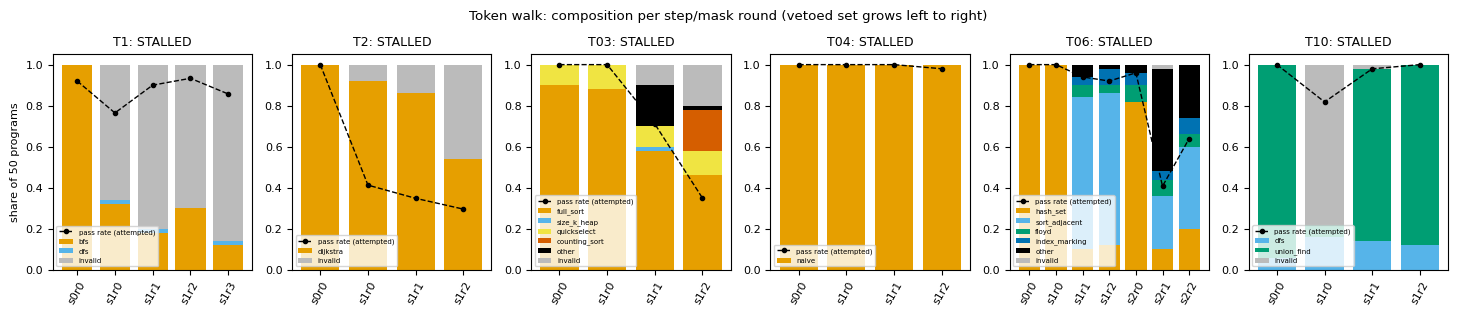

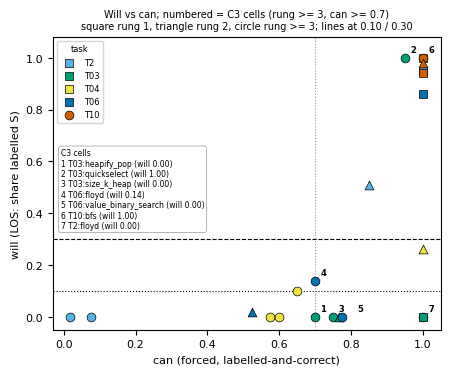

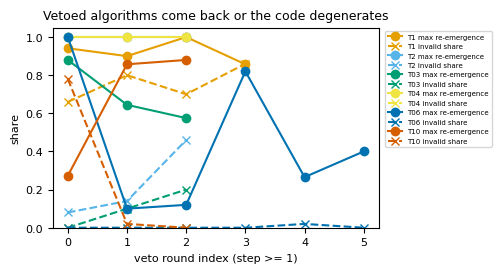

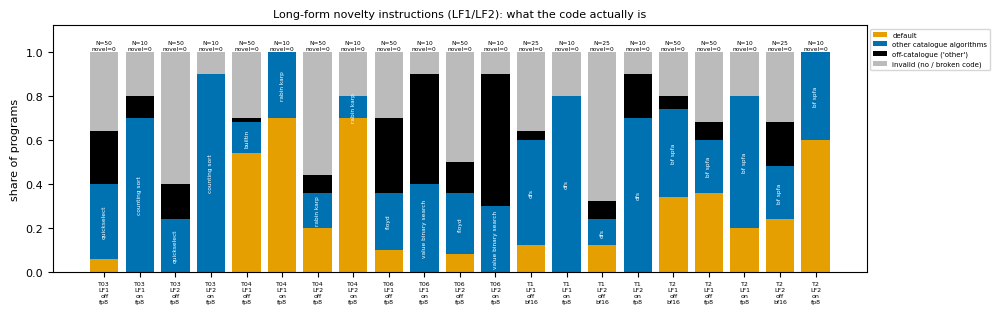

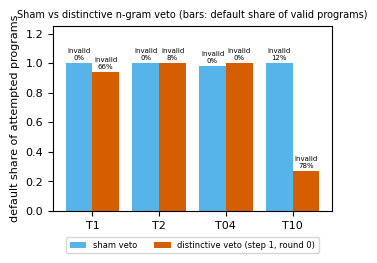

In [16]:
# ================================================================ src/figures.py (drawn only from results/*.json)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 8, "axes.titlesize": 9})
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999", "#000000"]


def colour_map(labels: list[str]) -> dict[str, str]:
    cm, i = {}, 0
    for l in labels:
        if l == "invalid":
            cm[l] = "#BBBBBB"
        elif l == "other":
            cm[l] = "#000000"
        else:
            cm[l] = OKABE[i % 7]
            i += 1
    return cm


def save(fig, name: str) -> None:
    for ext in ("pdf", "png"):
        fig.savefig(FIGS / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    plt.show()   # was: plt.close(fig) - show the figure inline as well


def fig_walk(walk: dict) -> None:
    tasks = [t for t in ALL_TASKS if isinstance(walk.get(t), dict) and walk[t].get("steps")]
    if not tasks:
        return
    fig, axes = plt.subplots(1, len(tasks), figsize=(3.0 * len(tasks), 2.8), squeeze=False)
    for ax, t in zip(axes[0], tasks):
        steps = walk[t]["steps"]
        labs = TASKS[t]["catalogue"] + ["other", "invalid"]
        cm = colour_map(labs)
        xs = [f"s{s['step']}r{s['round']}" for s in steps]
        bottom = [0.0] * len(steps)
        for l in labs:
            vals = [s["counts"].get(l, 0) / max(1, s["n"]) for s in steps]
            if sum(vals) == 0:
                continue
            ax.bar(xs, vals, bottom=bottom, color=cm[l], label=l, width=0.8)
            bottom = [b + v for b, v in zip(bottom, vals)]
        ax.plot(xs, [s["pass_rate"] or 0 for s in steps], "k--", marker="o", ms=3, lw=1, label="pass rate (attempted)")
        ax.set_title(f"{t}: {walk[t]['status']}")
        ax.set_ylim(0, 1.05)
        ax.tick_params(axis="x", rotation=60)
        ax.legend(fontsize=5, loc="lower left")
    axes[0][0].set_ylabel("share of 50 programs")
    fig.suptitle("Token walk: composition per step/mask round (vetoed set grows left to right)", y=1.04)
    save(fig, "fig1_token_walk")


def fig_will_can(c3: dict) -> None:
    cells = c3.get("cells", [])
    if not cells:
        return
    fig, ax = plt.subplots(figsize=(5.0, 3.8))
    seen = set()
    for c in cells:
        if c["will"] is None or c["can"] is None:
            continue
        mk = {1: "s", 2: "^"}.get(c["rung"], "o")
        col = OKABE[ALL_TASKS.index(c["task"]) % 7]
        lab = c["task"] if c["task"] not in seen else None
        seen.add(c["task"])
        ax.scatter(c["can"], c["will"], marker=mk, color=col, edgecolor="k", s=40, lw=0.5, label=lab,
                   zorder=3)
    q = sorted([c for c in cells if c.get("qualifies") and c["will"] is not None and c["can"] is not None],
               key=lambda c: (c["task"], c["S"]))
    key_lines = []
    for j, c in enumerate(q, 1):
        same = [x for x in q[:j - 1] if abs(x["can"] - c["can"]) < 0.03 and abs(x["will"] - c["will"]) < 0.03]
        ax.annotate(str(j), (c["can"], c["will"]), fontsize=6, xytext=(4 + 7 * len(same), 4),
                    textcoords="offset points", fontweight="bold")
        key_lines.append(f"{j} {c['task']}:{c['S']} (will {c['will']:.2f})")
    if key_lines:
        ax.text(0.02, 0.62, "C3 cells\n" + "\n".join(key_lines), transform=ax.transAxes, fontsize=5.5,
                va="top", bbox={"boxstyle": "round", "fc": "white", "ec": "#999999", "lw": 0.5})
    ax.axhline(0.10, color="k", ls=":", lw=0.8)
    ax.axhline(0.30, color="k", ls="--", lw=0.8)
    ax.axvline(0.7, color="#999999", ls=":", lw=0.8)
    ax.set_xlabel("can (forced, labelled-and-correct)")
    ax.set_ylabel("will (LOS: share labelled S)")
    ax.set_xlim(-0.03, 1.05)
    ax.set_ylim(-0.05, 1.08)
    ax.legend(fontsize=6, loc="upper left", title="task", title_fontsize=6)
    ax.set_title("Will vs can; numbered = C3 cells (rung >= 3, can >= 0.7)\n"
                 "square rung 1, triangle rung 2, circle rung >= 3; lines at 0.10 / 0.30", fontsize=7)
    save(fig, "fig2_will_vs_can")


def fig_reemergence(walk: dict) -> None:
    tasks = [t for t in ALL_TASKS if isinstance(walk.get(t), dict) and walk[t].get("steps")]
    if not tasks:
        return
    fig, ax = plt.subplots(figsize=(4.2, 2.6))
    for i, t in enumerate(tasks):
        steps = [s for s in walk[t]["steps"] if s["step"] >= 1]
        if not steps:
            continue
        xs = list(range(len(steps)))
        re = [max(s["reemergence"].values()) if s["reemergence"] else 0 for s in steps]
        inv = [s["invalid_share"] or 0 for s in steps]
        ax.plot(xs, re, marker="o", color=OKABE[i % 7], label=f"{t} max re-emergence")
        ax.plot(xs, inv, marker="x", ls="--", color=OKABE[i % 7], label=f"{t} invalid share")
    ax.set_xlabel("veto round index (step >= 1)")
    ax.set_ylabel("share")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=5, ncol=1, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_title("Vetoed algorithms come back or the code degenerates")
    save(fig, "fig3_reemergence")


def fig_longform(lf: dict) -> None:
    """Role-based colours (labels differ per task): default / other catalogue algorithms / off-catalogue / invalid;
    the modal non-default catalogue algorithm is written on each bar."""
    if not lf:
        return
    keys = list(lf)
    roles = [("default", OKABE[0]), ("other catalogue algorithms", OKABE[4]), ("off-catalogue ('other')", "#000000"),
             ("invalid (no / broken code)", "#BBBBBB")]
    fig, ax = plt.subplots(figsize=(max(5, 0.5 * len(keys)), 3.2))
    for i, k in enumerate(keys):
        t = k.split("|")[0]
        cnt, n = lf[k]["counts"], max(1, lf[k]["N"])
        D = TASKS[t]["default"]
        alt = {l: v for l, v in cnt.items() if l in TASKS[t]["catalogue"] and l != D}
        vals = [cnt.get(D, 0) / n, sum(alt.values()) / n, cnt.get("other", 0) / n, cnt.get("invalid", 0) / n]
        b = 0.0
        for (name, col), v in zip(roles, vals):
            ax.bar(i, v, bottom=b, color=col, label=name if i == 0 else None, width=0.8)
            b += v
        top = max(alt, key=alt.get) if alt else ""
        if top:
            ax.text(i, vals[0] + vals[1] / 2, top.replace("_", " "), ha="center", va="center", fontsize=4.2,
                    rotation=90, color="white")
        ax.text(i, 1.01, f"N={lf[k]['N']}\nnovel={lf[k]['novel_count']}", ha="center", fontsize=4.2)
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels([k.replace("|think_", "|").replace("|", "\n") for k in keys], fontsize=4.5)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("share of programs")
    ax.legend(fontsize=5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    ax.set_title("Long-form novelty instructions (LF1/LF2): what the code actually is", fontsize=8)
    save(fig, "fig4_longform")


def fig_sham(walk: dict) -> None:
    rows = [(t, walk[t]["sham_vs_distinctive"]) for t in ALL_TASKS if isinstance(walk.get(t), dict)
            and "sham_ngram" in (walk[t].get("sham_vs_distinctive") or {})]
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(3.6, 2.4))
    xs = range(len(rows))
    ax.bar([x - 0.2 for x in xs], [r["sham_default_share"] or 0 for _, r in rows], 0.4, color=OKABE[1],
           label="sham veto")
    ax.bar([x + 0.2 for x in xs], [r["distinctive_default_share"] or 0 for _, r in rows], 0.4, color=OKABE[5],
           label="distinctive veto (step 1, round 0)")
    for x, (_, r) in zip(xs, rows):
        ax.text(x + 0.2, (r["distinctive_default_share"] or 0) + 0.02,
                f"invalid\n{(r.get('distinctive_invalid_share') or 0):.0%}", ha="center", fontsize=5)
        ax.text(x - 0.2, (r["sham_default_share"] or 0) + 0.02,
                f"invalid\n{(r.get('sham_invalid_share') or 0):.0%}", ha="center", fontsize=5)
    ax.set_xticks(list(xs))
    ax.set_xticklabels([t for t, _ in rows])
    ax.set_ylabel("default share of attempted programs")
    ax.set_ylim(0, 1.25)
    ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
    ax.set_title("Sham vs distinctive n-gram veto (bars: default share of valid programs)", fontsize=7)
    save(fig, "fig5_sham_vs_distinctive")


# ---- the body of src/figures.py main()
def rj(n):
    p = RESULTS / n
    return json.loads(read_text(p)) if exists(p) else {}   # was: p.read_text() / p.exists()


walk = rj("walk.json")
fig_walk(walk)
fig_will_can(rj("c3.json"))
fig_reemergence(walk)
fig_longform(rj("longform.json"))
fig_sham(walk)

## Results 4: headline numbers in `metadata`

The verdicts `assemble_outputs()` copied into `method_out.json → metadata`:
- per task, the token walk's status and depth (rung 1 = still the default);
- the sham control;
- the fixed TOP5 veto;
- C3 per task;
- compliance with the two-step bans;
- the long-form novelty count;
- the commitment-chain check.

In [17]:
meta = out["metadata"]


def f2(x):
    return "-" if x is None else f"{x:.2f}"


walk_tab = []
for t in ALL_TASKS:
    w = meta["walk"][t]
    sv = w.get("sham_vs_distinctive") or {}
    has_sham = "sham_ngram" in sv
    walk_tab.append({"task": t, "default": TASKS[t]["default"], "walk status": w["status"],
                     "deepest rung": w["deepest_rung_reached"],
                     "rungs": " -> ".join(r["label"] for r in w["rungs"]),
                     "sham n-gram": repr(sv["sham_ngram"]) if has_sham else sv.get("status", "-"),
                     "default share sham | distinctive": (f"{f2(sv['sham_default_share'])} | "
                                                          f"{f2(sv['distinctive_default_share'])}" if has_sham else "-"),
                     "pass rate sham | distinctive": (f"{f2(sv.get('sham_pass_rate'))} | "
                                                      f"{f2(sv.get('distinctive_pass_rate'))}" if has_sham else "-")})
display(pd.DataFrame(walk_tab))

top5 = meta["fixed_top5_T1"]
print(f"fixed TOP5 veto on T1 (vetoes {', '.join(top5['targets'])} at once): final round {top5['final_round']['counts']},"
      f" avoidance {f2(top5['final_round']['avoidance'])}")
c3_tasks = {t: v["verdict"] for t, v in meta["c3"]["per_task"].items()}
print(f"C3 (will <= 0.10 wherever rung >= 3 and can >= 0.7): {meta['c3']['overall']}; per task {c3_tasks}")
two = {t: f"{v['avoidance']:.2f}" for t, v in meta["reach"]["two_step"].items()}
print(f"two-step bans {{default, R2}}, compliance (share avoiding both): {two}")
lf = meta["longform"]
print(f"long-form novelty instructions: {sum(v['N'] for v in lf.values())} outputs in {len(lf)} cells, "
      f"{sum(v['novel_count'] for v in lf.values())} novel; NOVEL count over all arms after the audit: "
      f"{meta['novel_count_all_arms']}")
cm = meta["commitments"]
print(f"commitment chain: {cm['n']} entries, all ok: {cm['ok']}; failing: {[b['label'] for b in cm['bad']]} (D17)")
print(f"metadata.versions (this environment): {meta['versions']}")

,task,default,walk status,deepest rung,rungs,sham n-gram,default share sham | distinctive,pass rate sham | distinctive
0,T1,bfs,STALLED,1,bfs,' start == goal:\n',1.00 | 0.94,0.96 | 0.76
1,T2,dijkstra,STALLED,1,dijkstra,"' u, v, w'",1.00 | 1.00,1.00 | 0.41
2,T03,full_sort,STALLED,1,full_sort,NOT_CONSTRUCTIBLE,-,-
3,T04,naive,STALLED,1,naive,' len',0.98 | 1.00,0.96 | 1.00
4,T06,hash_set,STALLED,2,hash_set -> sort_adjacent,NOT_CONSTRUCTIBLE,-,-
5,T10,union_find,STALLED,1,union_find,' range',1.00 | 0.27,1.00 | 0.82


fixed TOP5 veto on T1 (vetoes bfs, dfs, iddfs, astar_gbfs at once): final round {'invalid': 35, 'bfs': 13, 'dfs': 2}, avoidance 0.00
C3 (will <= 0.10 wherever rung >= 3 and can >= 0.7): DISCONFIRMED; per task {'T2': 'CONFIRMED', 'T03': 'DISCONFIRMED', 'T04': 'UNTESTABLE', 'T06': 'MIXED', 'T10': 'DISCONFIRMED'}
two-step bans {default, R2}, compliance (share avoiding both): {'T1': '0.02', 'T2': '0.01', 'T03': '1.00', 'T04': '0.14', 'T06': '0.96', 'T10': '1.00'}
long-form novelty instructions: 575 outputs in 21 cells, 0 novel; NOVEL count over all arms after the audit: 0
commitment chain: 49 entries, all ok: False; failing: ['code sha256 analysis.py before bench ban samples'] (D17)
metadata.versions (this environment): {'vllm': None, 'torch': None, 'transformers': None, 'numpy': '2.0.2', 'scipy': None}


## What this shows, and how to go further

**Findings**
- **The veto is exact, yet it does not move the algorithm.** No banned id sequence appeared in any vetoed generation, yet every walk stalled within two steps. Three things happened instead:
  - the default came back under new names (`current_row` / `current_col`) or new spellings, the string leaks;
  - or the code broke (T1: 66–86% invalid);
  - only T06 moved one rung, to sort + adjacent.
- **The sham controls rule out generic masking.** Vetoing an algorithm-generic n-gram of the same length and presence kept the default.
- **Neither ban knob reaches deeper.** Prompt bans substitute rather than subtract: quickselect is T03's answer to almost any list. The long-form "novel algorithm" instructions produce novelty *claims* and catalogue code. Across all arms the NOVEL count is 0.

**Fidelity** (checked when this notebook was built):
- The 100 examples assembled above are identical to the matching examples of the artifact's `full_method_out.json`.
- Every `metadata` field matches the artifact's except `utc` and `versions`, which describe the environment that runs the code.
- Rebuilt with all 1,750 rows, the notebook reproduces all 1,750 `token_walk` examples exactly.

**Scaling this notebook up**
- `MAX_ROWS_PER_FILE = None` (the final setting) uses all 100 demo rows.
- `python build_mini_demo_data.py <artifact folder> --tokenizer-json tokenizer.json --n-rows 1750` rebuilds the demo data with **every** token-walk row (1,750, 2.9 MB). It needs the artifact folder and the Qwen3-8B `tokenizer.json`; the download command is in the script's docstring.
- To rebuild the whole `method_out.json`, with all four datasets, run `uv run method.py` (no argument) in the artifact folder. It takes about a minute and needs no GPU.

**Re-running the experiment** needs the artifact's `.venv` (vLLM 0.11), `Qwen/Qwen3-8B` (bf16, revision `b968826d…`) and `Qwen/Qwen3-8B-FP8` on a GPU with ≥ 23 GB, plus an OpenRouter key for the judges. The commands are listed in the docstring above, in the order they were run.